
# Neural Networks in Keras
### Intro to Keras
Keras is an API that acts as an interface for Tensorflow. It is a popular choice for building neural networks, especially as you are first learning, since it abstracts away most of the complexities involved in deep learning. Another popular choice is Pytorch - while we will not formally cover Pytorch, you might want to challenge yourself to learn this library as well. More resources will be provided at the end of this topic.




To create a neural network in Keras, we can follow three easy steps:

1. Define our network structure
2. Compile our model
3. Fit our model

Let's try it on a classification problem!

**Import Libraries**

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

I0000 00:00:1793686687.300083    1795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793686688.310883    1795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


**Import Data**

The dataset is from [Data.World](https://data.world/), and the goal is to use basketball player statistics to predict whether or not an NBA Rookie will last at least 5 years in the league. The data is available on the classroom page.


The target column is defined as:

* y = 0 if career years played < 5  

* y = 1 if career years played >= 5

In [2]:
# Load data
filename = 'data/nba.csv'  # originally '/content/sample_data/nba.csv' in Colab

# Notice how we pass column names directly in the read_csv() method
df = pd.read_csv(filename, index_col='Name')

# Show head
df.head()

,GP,MIN,PTS,FGM,FGA,FG%,3P Made,3PA,3P%,FTM,FTA,FT%,OREB,DREB,REB,AST,STL,BLK,TOV,TARGET_5Yrs
Name,,,,,,,,,,,,,,,,,,,,
Brandon Ingram,36,27.4,7.4,2.6,7.6,34.7,0.5,2.1,25.0,1.6,2.3,69.9,0.7,3.4,4.1,1.9,0.4,0.4,1.3,0
Andrew Harrison,35,26.9,7.2,2.0,6.7,29.6,0.7,2.8,23.5,2.6,3.4,76.5,0.5,2.0,2.4,3.7,1.1,0.5,1.6,0
JaKarr Sampson,74,15.3,5.2,2.0,4.7,42.2,0.4,1.7,24.4,0.9,1.3,67.0,0.5,1.7,2.2,1.0,0.5,0.3,1.0,0
Malik Sealy,58,11.6,5.7,2.3,5.5,42.6,0.1,0.5,22.6,0.9,1.3,68.9,1.0,0.9,1.9,0.8,0.6,0.1,1.0,1
Matt Geiger,48,11.5,4.5,1.6,3.0,52.4,0.0,0.1,0.0,1.3,1.9,67.4,1.0,1.5,2.5,0.3,0.3,0.4,0.8,1


**Clean Data & Split into X & y**

In [3]:
# Drop missing values
df.dropna(inplace = True)

# Create X feature matrix and y target vector
X = df.drop(columns = 'TARGET_5Yrs')

y = df['TARGET_5Yrs']

/tmp/ipykernel_1795/3125855597.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace = True)


**Train/Test Split**

In [4]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=3) #default test size - 0.25

In [5]:
X_train.shape

(996, 19)

**Scale Data**

In [6]:
# Scale our data (Important to improve training efficiency)

# Instantiate scaler object
scaler = StandardScaler()

# Fit and transform on train data
X_train = scaler.fit_transform(X_train)

# Transform test data.
X_test = scaler.transform(X_test)

In [7]:
X_train

array([[ 0.98446314,  0.28332168,  0.34569356, ..., -0.05405889,
         1.02967992,  0.80636122],
       [ 1.21246576, -0.99110079, -1.18002221, ..., -0.78495462,
        -0.58828907, -0.1515448 ],
       [-0.66855589, -1.13537503, -0.54240965, ..., -0.78495462,
        -0.12601222, -0.83576338],
       ...,
       [-0.32655195, -0.64243804, -0.47409402, ..., -1.02858653,
         0.10512621, -0.56207595],
       [-1.58056638,  0.60793872, -0.38300651, ..., -0.05405889,
        -0.12601222, -0.69891966],
       [ 1.04146379,  0.00679605,  0.27737792, ...,  0.43320493,
         0.56740307,  0.6695175 ]], shape=(996, 19))

## Defining the neural network

**Step 1: Define our network structure**

The first thing we need to define is how many features we have in our X data. This will be used in our first hidden layer, in which we have to tell Keras how many features to be expecting from our input layer.

In [8]:
# Step 1: Define our network structure
# Save the number of features we have as our input shape
input_shape = X_train.shape[1]
input_shape

19

We can then define our model type. We will use a Sequential model - this means that our model layers are run sequentially. This is a very common type of model to use in Keras.

In [9]:
# Instantiate Sequential model object
model = Sequential()

We can now add our hidden layers! We will use two hidden layers in this example, but you can really use as few or as many as you want. However, be careful adding too many hidden layers, as this increases complexity, furthers the nature of the black box, and can lead to overfitting.

There are many types of layers in Keras and these refer to the type of neural network we are fitting. The most common layer is a Dense layer, which means that the network is fully connected.

Within a dense layer, we need to specify the number of neurons we want in that layer and the type of activation function we want to use. The number of neurons in each layer is ultimately up to you - as a general rule of thumb, use less than or equal to the number of features you have and decrease the number of neurons as you go through the network. Within hidden layers, it is common to use the ReLU function, as it tends to perform well.

In [10]:
# First hidden layer
model.add(Dense(19, # How many neurons you have in your first hidden layer
                input_dim = input_shape, # What is the shape of your input features (number of columns)
                activation = 'relu')) # What activation function are you using?
# Second hidden layer
model.add(Dense(10, # How many neurons you have in your second hidden layer
                activation = 'relu')) # What activation function are you using?

# #third hidden layer
# model.add(Dense(10, activation='relu'))

/venv/tf/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


E0000 00:00:1793686688.636616    1795 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


We then need to add our output layer. The output layer needs to have the number of nodes you want in your output layer (this is often 1, but can be more for multiclass classification) and the activation function for the specific task. The activation function determines the range of values that the output layer can and should take on.

For regression problems, we want to use the linear activation function.

For classification problems, we want to use the sigmoid activation function (for binary) and softmax (for multiclass)

In [11]:
# Output layer
model.add(Dense(1, activation = 'sigmoid'))

## Step 2: Compile our model

When compiling our model, we need to specify which loss function we are using and what optimizer we will use to fit. A common optimizer to choose is the Adam optimizer.

For regression problems, we would want to use a loss function like MSE.

For binary classification problems like this one, we want to use the binary cross-entropy loss. This can be abbreviated as "bce" in Keras.

For multiclass classification problems, we would use categorical cross-entropy.

In [12]:
# Step 2: Compile
model.compile(loss = 'bce', optimizer = 'adam')

## Step 3: Fit our model

We can finally fit our model to our training data! We often want to save the fitting process so we can visualize our loss over time.

In [13]:
# Step 3: Fit our model
history = model.fit(X_train, y_train,
                    validation_data = (X_test, y_test),
                    epochs=10)

Epoch 1/10


 1/32 ━━━━━━━━━━━━━━━━━━━━ 16s 517ms/step - loss: 0.8024

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.7355 - val_loss: 0.6524


Epoch 2/10


 1/32 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.6886

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6382 - val_loss: 0.6020


... (20 outputs left out)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5683 - val_loss: 0.5671


Epoch 10/10


 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.5343

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5644 - val_loss: 0.5639


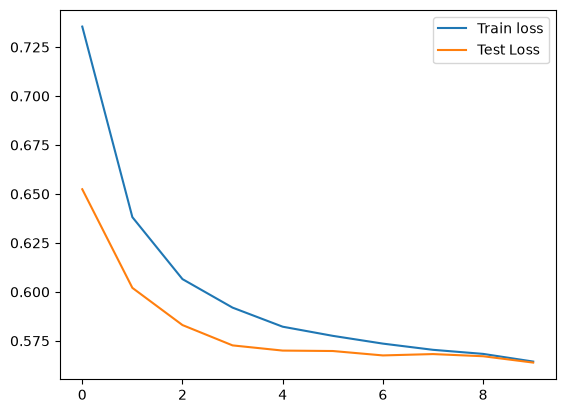

In [14]:
# Visualize the loss
plt.plot(history.history['loss'], label='Train loss') #training set
plt.plot(history.history['val_loss'], label='Test Loss') #testing set
plt.legend();

In [15]:
history.history

{'loss': [0.7354626655578613,
  0.6381588578224182,
  0.6065123081207275,
  0.5919519662857056,
  0.5822145938873291,
  0.577545166015625,
  0.5735762119293213,
  0.5704101920127869,
  0.568332314491272,
  0.5644115209579468],
 'val_loss': [0.6524045467376709,
  0.6020498871803284,
  0.5830501317977905,
  0.5726684927940369,
  0.5700183510780334,
  0.5697988271713257,
  0.5675448179244995,
  0.5682347416877747,
  0.5671330094337463,
  0.5638876557350159]}

We can see that as we increase the number of epochs we train our model for, both our training and validation loss decreases! This is exactly what we want, as we want the loss to be as low as possible. In reality, we would run our model for a lot more than 10 epochs.

# Assignment: Predicting Term-Deposit Subscription with a Neural Network

**Course:** Data Science in Python & Machine Learning: Deep Learning
**Format:** Individual Colab notebook. Explain your reasoning in markdown cells alongside your code.
**Due:** _[insert date]_

---

## Dataset

🔗 **Link:** https://archive.ics.uci.edu/dataset/222/bank+marketing
**Source:** UCI Machine Learning Repository, *Bank Marketing* (Moro, Cortez & Rita, 2014)
**File to use:** `bank-additional/bank-additional-full.csv` (41,188 rows, 20 features + target `y`)
**Column descriptions:** `bank-additional/bank-additional-names.txt` (included in the download)

### Background

A Portuguese bank ran phone marketing campaigns to sell term deposits. Each row is one customer who was contacted. Your task is to build a neural network that predicts whether a customer will **subscribe to a term deposit** (`y = yes/no`), so the marketing team can focus its calls on the customers most likely to say yes.

### Loading the data in Colab

```python
!wget -q https://archive.ics.uci.edu/static/public/222/bank+marketing.zip
!unzip -o -q bank+marketing.zip
!unzip -o -q bank-additional.zip

import pandas as pd
df = pd.read_csv('bank-additional/bank-additional-full.csv', sep=';')
print(df.shape)   # should be (41188, 21)
df.head()
```

> **Notes about the data:**
> - The file is separated by semicolons (`;`), not commas.
> - There are no `NaN`s. Missing values are recorded as the text `"unknown"`.
> - `pdays = 999` means the customer was **never contacted before**. It is not a real number of days.

---

## Part 1: Data Understanding and Preparation (20 marks)

1. Report the dataset's shape, data types and class balance of `y`. Check for duplicate rows.
2. Find which columns contain `"unknown"` and how many rows are affected. Decide how to handle them and justify your choice. *(Hint: count how many rows you would lose if you simply dropped them.)*
3. **Drop the `duration` column.** In a markdown cell, explain why it must not be used to build a realistic predictive model. *(Hint: read its description in `bank-additional-names.txt`. When is call duration known?)*
4. Convert `y` to 0/1 and one-hot encode the categorical columns.
5. Split the data into **train / validation / test (60 / 20 / 20)** using `stratify=y` and `random_state=42`.
6. Scale the numeric features **correctly**. Show clearly that the scaler was fitted on the training data only.

## Part 2: Baseline (10 marks)

7. What accuracy would a model that **always predicts "no"** achieve? Explain why accuracy is a misleading metric for this dataset.
8. Train a **logistic regression** model. Report precision, recall, F1 and ROC-AUC on the validation set. Your neural network should aim to beat this.

## Part 3: Your First Neural Network (20 marks)

9. Build a `Sequential` model with **2 hidden layers (ReLU)** and an appropriate output layer. Justify your choice of output activation and loss function.
10. Run `model.summary()`. **Calculate the number of parameters in the first hidden layer by hand** and show that it matches.
11. Compile with the Adam optimizer and `metrics=['accuracy', keras.metrics.AUC(name='auc')]`. Train for 50 epochs using your validation set.
12. Plot **training vs validation loss**. Is your model underfitting, overfitting or about right? Use the curves as evidence.

## Part 4: Experiments (30 marks)

For each experiment, show a plot **and** write 2–3 sentences interpreting what you see.

13. **Learning rate:** compare `0.0001`, `0.001` and `0.1`. Which converges best? What happens at `0.1`, and why?
14. **Capacity:** build a deliberately large model (for example 3 hidden layers of 256 neurons) and train it for 150 epochs. Show that it overfits.
15. **Regularisation:** add `Dropout` layers to the large model, then add `EarlyStopping(monitor='val_loss', restore_best_weights=True)`. At which epoch did training stop? Compare the curves with experiment 14.
16. **Activation functions:** replace ReLU with `linear` in the hidden layers. Compare the results with your logistic regression baseline and explain what you observe.

## Part 5: Final Evaluation and Business Interpretation (20 marks)

17. Choose your best model **using the validation set only**. Then evaluate it **once** on the test set. Report the confusion matrix, classification report and ROC-AUC.
18. Change the decision threshold (try `0.5`, `0.3` and `0.2`) and show how precision and recall change.
19. **Business memo (about 200 words, in markdown):** the marketing team has capacity for **1,000 calls**. Which threshold would you recommend, and why? Explain the cost to the bank of a **false positive** compared with a **false negative**.

---

## Bonus (up to 10 marks)

- Handle the class imbalance using `class_weight` in `model.fit()` and compare recall.
- Use Keras Tuner, or your own loop, to search over the number of layers and neurons.
- Build a gradient-boosted model (XGBoost or LightGBM). Was deep learning worth it on this tabular dataset? Discuss.

---

## Marking Rubric

| Area | Marks | What earns full marks |
|---|---|---|
| Data preparation | 20 | `"unknown"` handling justified, `duration` dropped and explained, correct encoding, no leakage in scaling |
| Baseline | 10 | Majority-class and logistic regression baselines with appropriate metrics |
| First neural network | 20 | Correct output layer and loss, parameter count verified by hand, curves diagnosed |
| Experiments | 30 | All 4 experiments run, plotted **and interpreted** |
| Evaluation and memo | 20 | Test set used once, threshold trade-off explained in business terms |
| **Total** | **100** | + up to 10 bonus marks |

## Submission

- Share your Colab notebook link (set to "Anyone with the link can view") by the due date.
- Make sure the notebook runs top to bottom without errors (**Runtime → Restart and run all**).
